<a href="https://colab.research.google.com/github/Rageel-28/244107020136-Machine-Learning/blob/main/JS09/JS09_05.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JS09 - Approximate Nearest Neighbors (ANN)
## Lab 5 - Uji Performansi ANN dengan Recall Query

Performa algoritma ANN dibandingkan dengan dua ukuran:
- **Recall@k**: dari $k$ tetangga sebenarnya, berapa proporsi yang ditemukan ANN.
- **QPS** (*queries per second*) / waktu per *query*: seberapa cepat pencarian.

Grafik yang ideal berada di **kanan atas** (*recall* tinggi dan cepat). Umumnya algoritma ANN menukar akurasi dengan kecepatan, sehingga satu algoritma menghasilkan **kurva** (bukan satu titik) saat parameter pencariannya diubah.

Standar acuan: [ANN-Benchmarks](https://github.com/erikbern/ann-benchmarks). Repositori itu membutuhkan Docker (tidak tersedia di Google Colab), sehingga di sini dipakai benchmark sederhana.

**Data:** vektor acak sintetis, $d=128$, `nb = 100.000` vektor *database*, `nq = 1.000` *query*, seed 42. **Parameter yang diuji:**

| Algoritma | Parameter tetap | Parameter yang divariasikan |
|---|---|---|
| ANNOY | `n_trees=10` | `search_k` = 200, 500, 1000, 2000 |
| FAISS IVF | `nlist=100` | `nprobe` = 1, 5, 10, 20 |
| HNSW | `M=16`, `ef_construction=200` | `ef` = 50, 100, 200, 400 |

In [1]:
# Instal library bila belum ada (di Colab setara dengan !pip install ...)
import importlib, subprocess, sys

for modul, paket in [('annoy', 'annoy'), ('faiss', 'faiss-cpu'), ('hnswlib', 'hnswlib'), ('matplotlib', 'matplotlib')]:
    try:
        importlib.import_module(modul)
    except ImportError:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', paket])

print('Library siap dipakai')

Library siap dipakai


## Langkah 1 - Dataset Acak dan Ground Truth

In [2]:
import numpy as np
import pandas as pd
import time
import faiss
from annoy import AnnoyIndex
import hnswlib
import matplotlib.pyplot as plt

# -------------------------------
# Dataset random
# -------------------------------
d = 128        # dimensi
nb = 100000    # jumlah database vector
nq = 1000      # jumlah query

np.random.seed(42)
xb = np.random.random((nb, d)).astype('float32')
xq = np.random.random((nq, d)).astype('float32')

# -------------------------------
# Ground truth dengan FAISS brute force
# -------------------------------
index_flat = faiss.IndexFlatL2(d)
index_flat.add(xb)
k = 10
t0 = time.perf_counter()
_, gt_idx = index_flat.search(xq, k)
t_flat = (time.perf_counter() - t0) * 1000 / nq
print(f'Ground truth selesai. Exact (FAISS Flat): {t_flat:.4f} ms/query')

Ground truth selesai. Exact (FAISS Flat): 1.0085 ms/query


## Langkah 2 - Fungsi Recall

In [3]:
# -------------------------------
# Fungsi recall
# -------------------------------
def recall_at_k(I_pred, I_gt, k):
    correct = 0
    for i in range(len(I_pred)):
        correct += len(set(I_pred[i][:k]) & set(I_gt[i][:k]))
    return correct / (len(I_pred) * k)

## Langkah 3 - Fungsi Benchmark

Struktur sama dengan modul (`run_annoy`, `run_faiss`, `run_hnsw`) dengan satu penyesuaian efisiensi: **indeks dibangun satu kali per algoritma**, lalu parameter pencarian (`search_k`, `nprobe`, `ef`) diubah-ubah. Pada modul, indeks dibangun ulang pada setiap nilai parameter sehingga lebih lama, padahal parameter pencarian tidak memengaruhi struktur indeks. Hasil *recall* tidak berubah karena indeks yang dibangun sama.

> **Catatan keadilan perbandingan:** FAISS dan HNSW (`knn_query` batch) memakai beberapa *thread* CPU, sedangkan ANNOY pada kode ini diproses satu per satu (satu *thread*). Atur `SATU_THREAD = True` untuk menyamakan jumlah *thread*; bawaan `False` mengikuti modul.

In [4]:
SATU_THREAD = False   # True -> FAISS dan HNSW dipaksa 1 thread agar adil terhadap ANNOY

if SATU_THREAD:
    faiss.omp_set_num_threads(1)

# -------------------------------
# Benchmark Annoy
# -------------------------------
def bangun_annoy(xb, n_trees=10):
    index = AnnoyIndex(xb.shape[1], 'euclidean')
    for i, v in enumerate(xb):
        index.add_item(i, v)
    index.build(n_trees)
    return index


def run_annoy(index, xq, search_k=1000, k=10):
    start = time.time()
    I = [index.get_nns_by_vector(v, k, search_k=search_k) for v in xq]
    elapsed = (time.time() - start) * 1000 / len(xq)  # ms/query
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed


# -------------------------------
# Benchmark FAISS IVF
# -------------------------------
def bangun_faiss(xb, nlist=100):
    quantizer = faiss.IndexFlatL2(d)
    index = faiss.IndexIVFFlat(quantizer, d, nlist, faiss.METRIC_L2)
    index.train(xb)
    index.add(xb)
    return index


def run_faiss(index, xq, nprobe=10, k=10):
    index.nprobe = nprobe
    start = time.time()
    _, I = index.search(xq, k)
    elapsed = (time.time() - start) * 1000 / len(xq)
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed


# -------------------------------
# Benchmark HNSW
# -------------------------------
def bangun_hnsw(xb, M=16):
    p = hnswlib.Index(space='l2', dim=d)
    p.init_index(max_elements=xb.shape[0], ef_construction=200, M=M)
    if SATU_THREAD:
        p.set_num_threads(1)
    p.add_items(xb)
    return p


def run_hnsw(p, xq, ef=100, k=10):
    p.set_ef(ef)
    start = time.time()
    I, _ = p.knn_query(xq, k)
    elapsed = (time.time() - start) * 1000 / len(xq)
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

## Langkah 4 - Membangun Indeks

In [5]:
waktu_build = {}

t0 = time.time(); idx_annoy = bangun_annoy(xb, n_trees=10);  waktu_build['ANNOY'] = time.time() - t0
t0 = time.time(); idx_faiss = bangun_faiss(xb, nlist=100);   waktu_build['FAISS IVF'] = time.time() - t0
t0 = time.time(); idx_hnsw = bangun_hnsw(xb, M=16);          waktu_build['HNSW'] = time.time() - t0

for nama, w in waktu_build.items():
    print(f'Build {nama:<10}: {w:8.2f} detik')

Build ANNOY     :     4.82 detik
Build FAISS IVF :     1.52 detik
Build HNSW      :    89.47 detik


## Langkah 5 - Menjalankan Benchmark dengan Beberapa Parameter

In [6]:
# -------------------------------
# Jalankan benchmark dengan beberapa parameter
# -------------------------------
results = {"Annoy": [], "Faiss": [], "HNSW": []}
param = {"Annoy": [], "Faiss": [], "HNSW": []}

# Annoy
for sk in [200, 500, 1000, 2000]:
    rec, t = run_annoy(idx_annoy, xq, search_k=sk)
    results["Annoy"].append((rec, t)); param["Annoy"].append(f'search_k={sk}')

# FAISS
for npb in [1, 5, 10, 20]:
    rec, t = run_faiss(idx_faiss, xq, nprobe=npb)
    results["Faiss"].append((rec, t)); param["Faiss"].append(f'nprobe={npb}')

# HNSW
for ef in [50, 100, 200, 400]:
    rec, t = run_hnsw(idx_hnsw, xq, ef=ef)
    results["HNSW"].append((rec, t)); param["HNSW"].append(f'ef={ef}')

baris = []
for algo in results:
    for (rec, t), pr in zip(results[algo], param[algo]):
        baris.append({'Algoritma': algo, 'Parameter': pr, 'Recall@10': rec,
                      'Query (ms/query)': t, 'QPS': 1000 / t})
tabel = pd.DataFrame(baris)
tabel.round(4)

,Algoritma,Parameter,Recall@10,Query (ms/query),QPS
0,Annoy,search_k=200,0.0221,0.0814,12284.5570
1,Annoy,search_k=500,0.0453,0.1418,7053.8621
2,Annoy,search_k=1000,0.0772,0.2411,4147.1386
3,Annoy,search_k=2000,0.1331,0.4749,2105.4887
4,Faiss,nprobe=1,0.0554,0.0490,20416.4975
5,Faiss,nprobe=5,0.1912,0.2194,4558.1293
6,Faiss,nprobe=10,0.3182,0.4634,2158.1699
7,Faiss,nprobe=20,0.5009,0.8943,1118.1984
8,HNSW,ef=50,0.2973,0.2085,4796.7521
9,HNSW,ef=100,0.4397,0.3417,2926.4369


## Langkah 6 - Visualisasi Trade-off

**Grafik 1** mengikuti modul: sumbu Y = waktu *query* (skala log) yang **dibalik**, sehingga makin ke atas = makin cepat, dan makin ke kanan = *recall* makin tinggi. Posisi ideal: kanan atas.

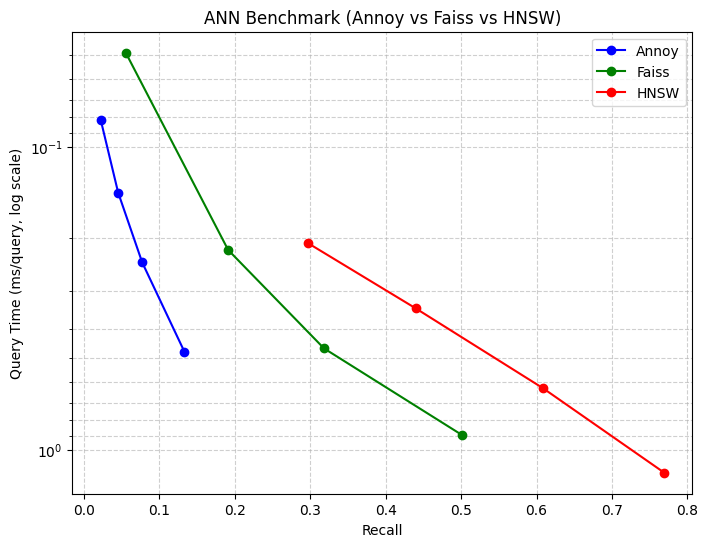

In [7]:
# -------------------------------
# Visualisasi trade-off
# -------------------------------
plt.figure(figsize=(8,6))
for label, color in zip(results.keys(), ["blue","green","red"]):
    recall, qtime = zip(*results[label])
    plt.plot(recall, qtime, marker="o", label=label, color=color)

plt.xlabel("Recall")
plt.ylabel("Query Time (ms/query, log scale)")
plt.yscale("log")
plt.gca().invert_yaxis()  # invert Y, makin atas = makin cepat
plt.title("ANN Benchmark (Annoy vs Faiss vs HNSW)")
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.show()

**Grafik 2** menampilkan hal yang sama dengan sumbu Y = **QPS** (tanpa dibalik), cara membaca yang lebih umum pada ANN-Benchmarks.

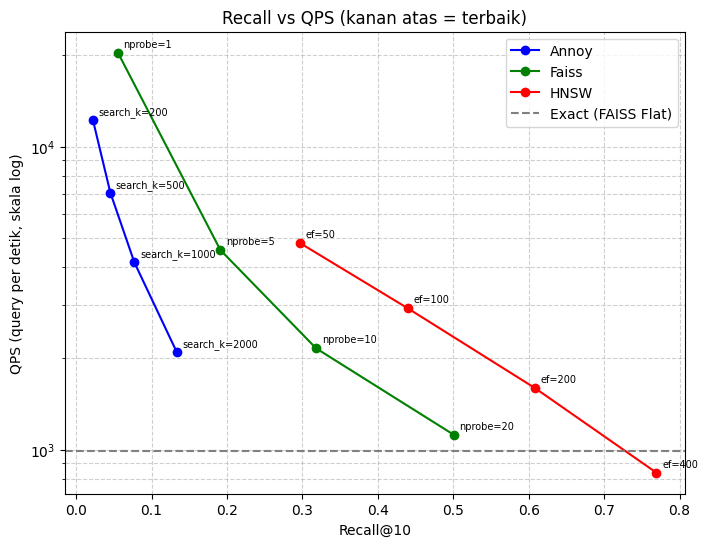

In [8]:
plt.figure(figsize=(8,6))
for algo, color in zip(['Annoy', 'Faiss', 'HNSW'], ["blue","green","red"]):
    sub = tabel[tabel.Algoritma == algo]
    plt.plot(sub['Recall@10'], sub['QPS'], marker='o', label=algo, color=color)
    for _, r in sub.iterrows():
        plt.annotate(r['Parameter'], (r['Recall@10'], r['QPS']), fontsize=7, xytext=(4, 4), textcoords='offset points')

plt.axhline(1000 / t_flat, color='gray', linestyle='--', label='Exact (FAISS Flat)')
plt.xlabel('Recall@10')
plt.ylabel('QPS (query per detik, skala log)')
plt.yscale('log')
plt.title('Recall vs QPS (kanan atas = terbaik)')
plt.legend()
plt.grid(True, which='both', ls='--', alpha=0.6)
plt.show()

In [9]:
# Ringkasan otomatis dari tabel di atas
print(f'Exact (FAISS Flat): {1000 / t_flat:,.0f} QPS (recall = 1.0)')
print()
for algo in ['Annoy', 'Faiss', 'HNSW']:
    sub = tabel[tabel.Algoritma == algo]
    terbaik = sub.loc[sub['Recall@10'].idxmax()]
    tercepat = sub.loc[sub['QPS'].idxmax()]
    print(f"{algo:<6} | recall tertinggi {terbaik['Recall@10']:.3f} ({terbaik['Parameter']}, {terbaik['QPS']:,.0f} QPS)"
          f" | tercepat {tercepat['QPS']:,.0f} QPS ({tercepat['Parameter']}, recall {tercepat['Recall@10']:.3f})")

Exact (FAISS Flat): 992 QPS (recall = 1.0)

Annoy  | recall tertinggi 0.133 (search_k=2000, 2,105 QPS) | tercepat 12,285 QPS (search_k=200, recall 0.022)
Faiss  | recall tertinggi 0.501 (nprobe=20, 1,118 QPS) | tercepat 20,416 QPS (nprobe=1, recall 0.055)
HNSW   | recall tertinggi 0.769 (ef=400, 839 QPS) | tercepat 4,797 QPS (ef=50, recall 0.297)


### Analisis

Hasil run (100.000 vektor acak 128D, 1.000 *query*, $k=10$). Waktu bergantung mesin; *Exact* (FAISS Flat) ±1938 QPS.

| Algoritma | Parameter | Recall@10 | QPS |
|---|---|---|---|
| ANNOY | `search_k` 200 → 2000 | 0.021 → 0.130 | 20973 → 5228 |
| FAISS IVF | `nprobe` 1 → 20 | 0.053 → 0.501 | 49853 → 4875 |
| HNSW | `ef` 50 → 400 | 0.298 → 0.771 | 19445 → 3177 |

**1. Setiap algoritma membentuk kurva trade-off.** Menaikkan parameter pencarian (`search_k`, `nprobe`, `ef`) menaikkan recall dan menurunkan QPS pada ketiganya. Maka membandingkan algoritma pada satu parameter saja tidak adil; yang dibandingkan adalah kurvanya.

**2. HNSW memiliki kurva terbaik pada rentang yang diuji bersama.** Pada recall ±0.3, HNSW (`ef=50`: recall 0.298, 19445 QPS) sekitar 1.8× lebih cepat daripada FAISS IVF pada recall yang sama (interpolasi linear kasar antara `nprobe=5` dan `nprobe=10`). Pada recall ±0.5 selisihnya sekitar 2× (HNSW antara `ef=100` dan `ef=200`, FAISS `nprobe=20` ±4875 QPS). ANNOY paling lemah: recall tertingginya hanya 0.130, dan pada QPS yang mirip (±5000) recall FAISS dan HNSW jauh lebih tinggi. FAISS IVF memiliki titik tercepat (`nprobe=1`, ±49853 QPS) tetapi dengan recall hanya 0.053; HNSW tidak diuji pada recall serendah itu sehingga tidak dapat dibandingkan di sana.

**3. Recall seluruhnya rendah karena datanya sulit, bukan hanya karena algoritmanya.** Vektor acak seragam 128D tidak memiliki struktur *cluster*: jarak ke tetangga terdekat hampir sama dengan jarak ke titik lain (*curse of dimensionality*), sehingga pencarian aproksimasi sulit membedakan tetangga sebenarnya. Pada data nyata seperti *embedding* teks/citra yang terstruktur, recall untuk parameter yang sama biasanya jauh lebih tinggi. **Angka mutlak ini tidak boleh digeneralisasi**; yang berlaku umum adalah bentuk *trade-off*-nya.

**4. Semua pengaturan ANN lebih cepat dari Exact, tetapi keuntungannya kecil.** Pengaturan paling lambat pun (HNSW `ef=400`, ±3177 QPS, recall 0.771) hanya ±1.6× lebih cepat dari FAISS Flat (±1938 QPS), karena `IndexFlat` memakai operasi matriks yang sangat teroptimasi. Pada data sulit seperti ini, untuk recall mendekati 1, pencarian *exact* tetap kompetitif.

**5. Catatan keadilan:** FAISS dan HNSW memakai banyak *thread* pada pencarian *batch* sedangkan ANNOY satu *thread*; atur `SATU_THREAD = True` untuk membandingkan secara adil.